In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
file_path="/content/redcap.premo_dataverse.xlsx"

In [ ]:
import os
os.listdir("/content")

['.config', 'redcap.premo_dataverse.xlsx', 'drive', 'sample_data']

In [ ]:
xls= pd.ExcelFile(file_path)

In [ ]:
xls.sheet_names

['metadata',
 'Demographic and Perinatal data',
 'Discharge & Outcomes data',
 'Sepsis or NEC eval data',
 'Intubation eval data']

In [ ]:
demographic= pd.read_excel(
    file_path,
    sheet_name="Demographic and Perinatal data"

)


In [ ]:
demographic.head()

,redcap_event_name,vsdata_yn,demograph_birth_ga_weeks,demograph_birth_ga_days,demograph_gender,demograph_race,presumed_race___1,demograph_ethnicity,dem_adi,multiples,...,eos_organism,eos_abx_days,eos_contaminant,los_num,perinatal_data_complete,site_id,demograph_birthtime_utc_10m,demograph_birth_year,demograph_admit_age_us,subject_number_deid
0,Demographic and Perinatal data,NaN,34.0,NaN,Male,White or Caucasian,NaN,Hispanic or Latino,73.0,Yes,...,NaN,NaN,NaN,0.0,Complete,1,22:20:00,2012.0,NaN,1636200
1,Demographic and Perinatal data,NaN,24.0,6.0,Female,Black or African American,NaN,Non-Hispanic or Non-Latino,NaN,No,...,NaN,NaN,NaN,5.0,Complete,1,04:00:00,2012.0,1.0,1362800
2,Demographic and Perinatal data,NaN,26.0,6.0,Male,White or Caucasian,NaN,Unknown/Not Reported,57.0,Yes,...,NaN,NaN,NaN,4.0,Complete,1,17:10:00,2012.0,17.0,1095800
3,Demographic and Perinatal data,NaN,28.0,2.0,Female,White or Caucasian,NaN,Unknown/Not Reported,63.0,No,...,NaN,7.0,NaN,1.0,Complete,1,19:10:00,2012.0,NaN,1377200
4,Demographic and Perinatal data,NaN,30.0,6.0,Male,Black or African American,NaN,Non-Hispanic or Non-Latino,30.0,No,...,NaN,7.0,NaN,0.0,Complete,1,02:40:00,2012.0,NaN,1361800


In [ ]:
demographic.shape

(6837, 34)

In [ ]:
demographic.columns

Index(['redcap_event_name', 'vsdata_yn', 'demograph_birth_ga_weeks',
       'demograph_birth_ga_days', 'demograph_gender', 'demograph_race',
       'presumed_race___1', 'demograph_ethnicity', 'dem_adi', 'multiples',
       'indication_for_delivery', 'if_other_indication_for_de', 'pprom',
       'demographics_complete', 'delivery_birth_weight',
       'delivery_apgar_1_min', 'delivery_apgar_5_min', 'delivery_apgar_10_min',
       'delivery_steroid_dose', 'delivery_mode', 'delivery_admin_type',
       'delivery_admit_age', 'eos_yn', 'eos_positive', 'eos_organism',
       'eos_abx_days', 'eos_contaminant', 'los_num', 'perinatal_data_complete',
       'site_id', 'demograph_birthtime_utc_10m', 'demograph_birth_year',
       'demograph_admit_age_us', 'subject_number_deid'],
      dtype='object')

In [ ]:
demographic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6837 entries, 0 to 6836
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   redcap_event_name            6837 non-null   object 
 1   vsdata_yn                    1921 non-null   object 
 2   demograph_birth_ga_weeks     6836 non-null   float64
 3   demograph_birth_ga_days      5421 non-null   float64
 4   demograph_gender             6834 non-null   object 
 5   demograph_race               6786 non-null   object 
 6   presumed_race___1            7 non-null      object 
 7   demograph_ethnicity          5867 non-null   object 
 8   dem_adi                      4537 non-null   float64
 9   multiples                    5556 non-null   object 
 10  indication_for_delivery      3924 non-null   object 
 11  if_other_indication_for_de   475 non-null    object 
 12  pprom                        3900 non-null   object 
 13  demographics_compl

In [ ]:
demographic.isna().sum()

,0
redcap_event_name,0
vsdata_yn,4916
demograph_birth_ga_weeks,1
demograph_birth_ga_days,1416
demograph_gender,3
demograph_race,51
presumed_race___1,6830
demograph_ethnicity,970
dem_adi,2300
multiples,1281


In [ ]:
missing_percent = demographic.isna().mean() * 100

In [ ]:
missing_percent.sort_values(ascending=False)

,0
presumed_race___1,99.897616
eos_organism,98.113208
eos_contaminant,97.103993
if_other_indication_for_de,93.052508
delivery_apgar_10_min,77.914290
vsdata_yn,71.902881
delivery_admit_age,46.336112
demograph_admit_age_us,46.336112
eos_abx_days,43.366974
pprom,42.957437


In [ ]:
missing_summary=pd.DataFrame({
    "missing_count": demographic.isna().sum(),
    "missing_percent": demographic.isna().mean() * 100


})

In [ ]:
missing_summary

,missing_count,missing_percent
redcap_event_name,0,0.000000
vsdata_yn,4916,71.902881
demograph_birth_ga_weeks,1,0.014626
demograph_birth_ga_days,1416,20.710838
demograph_gender,3,0.043879
demograph_race,51,0.745941
presumed_race___1,6830,99.897616
demograph_ethnicity,970,14.187509
dem_adi,2300,33.640486
multiples,1281,18.736288


In [ ]:
demographic["demograph_gender"].value_counts(dropna=False)

,count
demograph_gender,
Male,3431
Female,3403
NaN,3


In [ ]:
outcomes= pd.read_excel (
    file_path,
    sheet_name="Discharge & Outcomes data"

)

In [ ]:
outcomes.head()

,redcap_event_name,ivh_grade,bpd_36_weeks,rop_laser_avastin,bayley_yn,bayley_version,bayley_cog,bayeley_lang,bayley_motor,outcomes_data_complete,...,death_cause___5,death_cause___6,death_cause___7,death_cause___8,death_cause___9,discharge_or_death_complete,site_id,bayley_age_us,disch_age_us,subject_number_deid
0,Discharge & Outcomes data,0.0,No,No,NaN,NaN,NaN,NaN,NaN,Complete,...,NaN,NaN,NaN,NaN,NaN,Complete,1,NaN,17.0,1636200
1,Discharge & Outcomes data,2.0,No,No,NaN,NaN,NaN,NaN,NaN,Complete,...,NaN,NaN,NaN,NaN,NaN,Complete,1,NaN,91.0,1362800
2,Discharge & Outcomes data,3.0,Yes,No,NaN,NaN,NaN,NaN,NaN,Complete,...,NaN,NaN,NaN,NaN,NaN,Complete,1,NaN,85.0,1095800
3,Discharge & Outcomes data,2.0,No,No,NaN,NaN,NaN,NaN,NaN,Complete,...,NaN,NaN,NaN,NaN,NaN,Complete,1,NaN,61.0,1377200
4,Discharge & Outcomes data,0.0,No,No,NaN,NaN,NaN,NaN,NaN,Complete,...,NaN,NaN,NaN,NaN,NaN,Complete,1,NaN,34.0,1361800


In [ ]:
outcomes["bpd_36_weeks"].value_counts(dropna=False)

,count
bpd_36_weeks,
NaN,2309
No,2265
Yes,1652
Unknown,339


In [ ]:
metadata = pd.read_excel(
    file_path,
    sheet_name="metadata"
)
print(metadata.shape)

(77, 18)


In [ ]:
metadata[metadata.astype(str).apply(
    lambda row: row.str.contains("bpd_36_weeks", case=False).any(),
    axis=1
)]

,field_name,form_name,section_header,field_type,field_label,select_choices_or_calculations,field_note,text_validation_type_or_show_slider_number,text_validation_min,text_validation_max,identifier,branching_logic,required_field,custom_alignment,question_number,matrix_group_name,matrix_ranking,field_annotation
27,bpd_36_weeks,outcomes_data,NaN,radio,Did the infant require supplemental oxygen at ...,"1, Yes | 0, No | 99, Unknown",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
outcomes=pd.read_excel(
    file_path,
    sheet_name="Discharge & Outcomes data"
)

In [ ]:
outcomes.shape

(6565, 26)

In [ ]:
outcomes ["subject_number_deid"].nunique()

6565

In [ ]:
demographic["subject_number_deid"].nunique()

6837

In [ ]:
demographic_only = demographic[
    ~demographic["subject_number_deid"].isin(
        outcomes["subject_number_deid"]
    )
]

In [ ]:
demographic_only.shape

(272, 34)

In [ ]:
demographic_only.head()

,redcap_event_name,vsdata_yn,demograph_birth_ga_weeks,demograph_birth_ga_days,demograph_gender,demograph_race,presumed_race___1,demograph_ethnicity,dem_adi,multiples,...,eos_organism,eos_abx_days,eos_contaminant,los_num,perinatal_data_complete,site_id,demograph_birthtime_utc_10m,demograph_birth_year,demograph_admit_age_us,subject_number_deid
1541,Demographic and Perinatal data,NaN,28.0,0.0,Male,White or Caucasian,Race was presumed,Hispanic or Latino,37.0,No,...,NaN,5.0,NaN,4.0,Complete,1,07:10:00,2025.0,NaN,1941300
1549,Demographic and Perinatal data,NaN,22.0,6.0,Female,Black or African American,NaN,Unknown/Not Reported,59.0,No,...,NaN,5.0,NaN,10.0,Complete,1,06:10:00,2025.0,NaN,1744100
1559,Demographic and Perinatal data,NaN,28.0,1.0,Male,NaN,NaN,Unknown/Not Reported,98.0,No,...,NaN,NaN,NaN,NaN,Incomplete,1,21:50:00,2025.0,117.0,1081300
1560,Demographic and Perinatal data,NaN,31.0,NaN,Male,White or Caucasian,NaN,Non-Hispanic or Non-Latino,57.0,No,...,NaN,NaN,NaN,NaN,Incomplete,1,07:30:00,2025.0,0.0,1085800
1561,Demographic and Perinatal data,NaN,25.0,NaN,Female,Black or African American,NaN,Non-Hispanic or Non-Latino,59.0,No,...,NaN,NaN,NaN,NaN,Incomplete,1,10:20:00,2025.0,NaN,1555400


In [ ]:
merged = demographic.merge(
    outcomes,
    on="subject_number_deid",
    how="inner"
)

In [ ]:
merged.shape

(6565, 59)

In [ ]:
demographic_only[[
    "subject_number_deid",
    "demograph_birth_ga_weeks",
    "delivery_birth_weight",
    "delivery_apgar_1_min",
    "delivery_apgar_5_min"
]].head()

,subject_number_deid,demograph_birth_ga_weeks,delivery_birth_weight,delivery_apgar_1_min,delivery_apgar_5_min
1541,1941300,28.0,1020.0,1.0,5.0
1549,1744100,22.0,496.0,6.0,3.0
1559,1081300,28.0,1270.0,1.0,3.0
1560,1085800,31.0,1420.0,4.0,6.0
1561,1555400,25.0,896.0,1.0,4.0


In [ ]:
merged.shape

(6565, 59)

In [ ]:
merged["bpd_36_weeks"].value_counts(dropna=False)

,count
bpd_36_weeks,
NaN,2309
No,2265
Yes,1652
Unknown,339


In [ ]:
merged["bpd_36_weeks"].value_counts(
    normalize=True,
    dropna=False)


,proportion
bpd_36_weeks,
NaN,0.351714
No,0.345011
Yes,0.251637
Unknown,0.051637


In [ ]:
analytical_data = merged[
    merged["bpd_36_weeks"].isin(["Yes", "No"])
]

In [ ]:
analytical_data.shape

(3917, 59)

In [ ]:
analytical_data["bpd_36_weeks"].value_counts()

,count
bpd_36_weeks,
No,2265
Yes,1652


In [ ]:
bpd_counts = analytical_data["bpd_36_weeks"].value_counts()

In [ ]:
bpd_counts

,count
bpd_36_weeks,
No,2265
Yes,1652


In [ ]:
bpd_counts = bpd_counts.reset_index()

In [ ]:
bpd_counts

,bpd_36_weeks,count
0,No,2265
1,Yes,1652


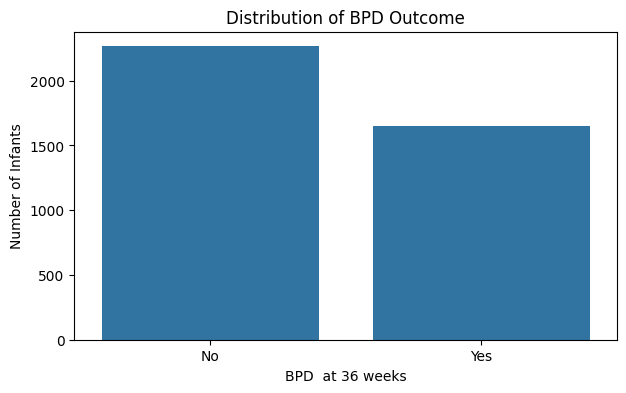

In [ ]:
plt.figure(figsize=(7,4))
sns.barplot(
    data=bpd_counts,
    x="bpd_36_weeks",
    y="count"
)
plt.title("Distribution of BPD Outcome")
plt.xlabel("BPD  at 36 weeks")
plt.ylabel("Number of Infants")
plt.show()

<Axes: xlabel='bpd_36_weeks', ylabel='demograph_birth_ga_weeks'>

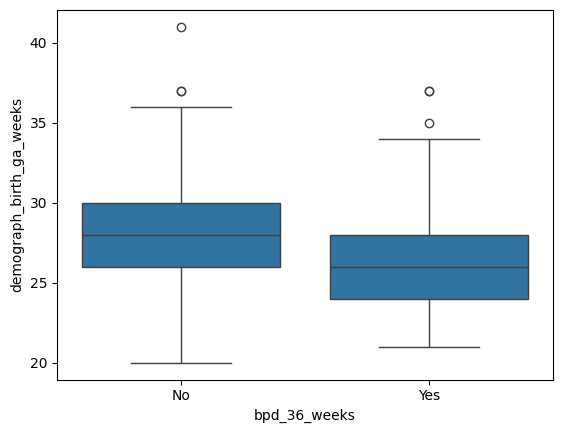

In [ ]:
sns.boxplot(
    data=analytical_data,
    x="bpd_36_weeks",
    y="demograph_birth_ga_weeks"
)

In [ ]:
data= analytical_data

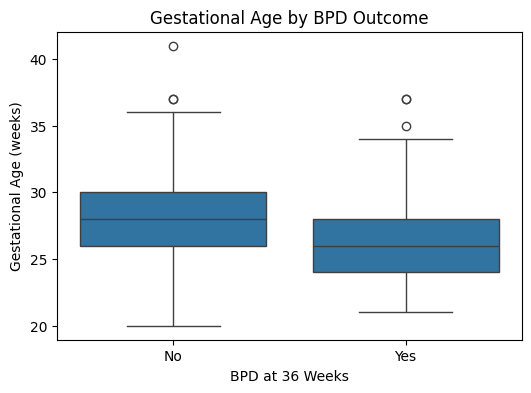

In [ ]:
plt.figure(figsize=(6, 4))

sns.boxplot(
    data=analytical_data,
    x="bpd_36_weeks",
    y="demograph_birth_ga_weeks"
)

plt.title("Gestational Age by BPD Outcome")
plt.xlabel("BPD at 36 Weeks")
plt.ylabel("Gestational Age (weeks)")

plt.show()

<Axes: xlabel='bpd_36_weeks', ylabel='delivery_birth_weight'>

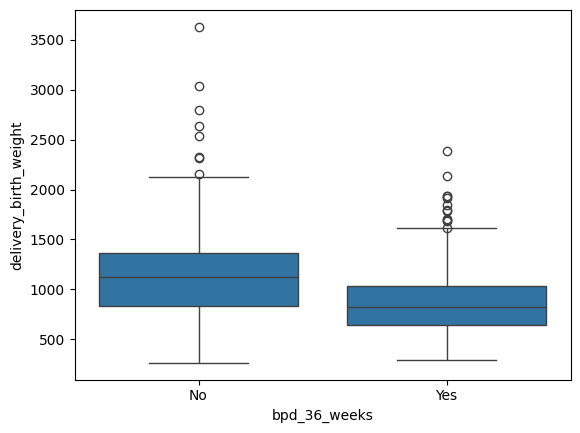

In [ ]:
sns.boxplot(data=analytical_data,
            x="bpd_36_weeks",
            y="delivery_birth_weight"
            )

<Axes: xlabel='bpd_36_weeks', ylabel='delivery_birth_weight'>

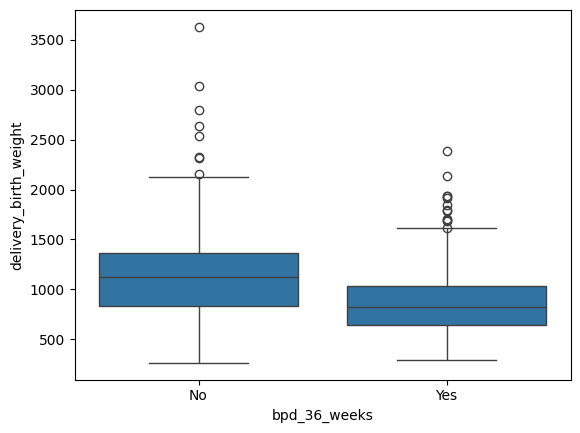

In [ ]:
sns.boxplot(
    data= analytical_data,
    x="bpd_36_weeks",
    y="delivery_birth_weight"
)

<Axes: xlabel='bpd_36_weeks', ylabel='delivery_apgar_1_min'>

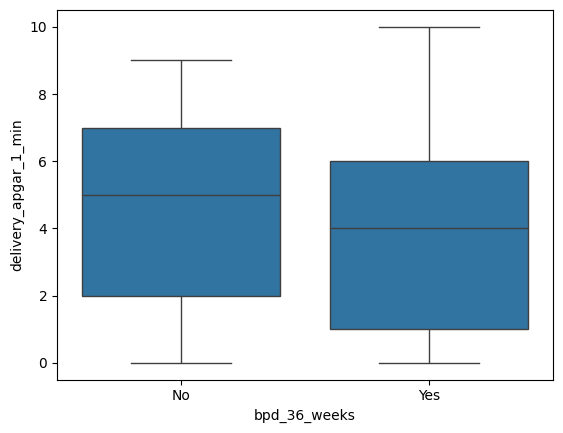

In [ ]:
sns.boxplot(
    data=analytical_data,
    x="bpd_36_weeks",
    y="delivery_apgar_1_min"
)

In [ ]:
sns.boxplot(
    data=analyticl_data,
    x="bpd_36_weeks"
)

In [ ]:
analytical_data.isna().sum().sort_values(ascending=False).head(15)

,0
presumed_race___1,3914
death_cause___8,3907
death_cause___6,3891
death_cause___3,3870
death_cause___5,3859
death_cause___2,3858
death_cause___7,3856
death_cause___4,3833
eos_organism,3816
death_cause___9,3794


In [ ]:
analytical_data.isna().sum() / analytical_data.shape[0] * 100

,0
redcap_event_name_x,0.000000
vsdata_yn,58.514169
demograph_birth_ga_weeks,0.000000
demograph_birth_ga_days,2.757212
demograph_gender,0.051059
demograph_race,0.740363
presumed_race___1,99.923411
demograph_ethnicity,0.485065
dem_adi,23.436303
multiples,3.267807


In [ ]:
missing_percent = (
    analytical_data.isna().sum()
    / analytical_data.shape[0]
    * 100
).sort_values(ascending=False)

missing_percent

,0
presumed_race___1,99.923411
death_cause___8,99.744703
death_cause___6,99.336227
death_cause___3,98.800102
death_cause___5,98.519275
death_cause___2,98.493745
death_cause___7,98.442686
death_cause___4,97.855502
eos_organism,97.421496
death_cause___9,96.859842


In [ ]:
analytical_data[
    [
        "bpd_36_weeks",
        "demograph_birth_ga_weeks",
        "delivery_birth_weight",
        "delivery_apgar_1_min",
        "delivery_apgar_5_min",
        "delivery_steroid_dose",
        "delivery_mode",
        "demograph_gender",
        "multiples",
        "pprom",
        "indication_for_delivery",
        "ivh_grade"
    ]
].dtypes

,0
bpd_36_weeks,object
demograph_birth_ga_weeks,float64
delivery_birth_weight,float64
delivery_apgar_1_min,float64
delivery_apgar_5_min,float64
delivery_steroid_dose,object
delivery_mode,object
demograph_gender,object
multiples,object
pprom,object


In [ ]:
categorical_columns = [
    "delivery_steroid_dose",
    "delivery_mode",
    "demograph_gender",
    "multiples",
    "pprom",
    "indication_for_delivery"
]

for column in categorical_columns:
    print("\n", column)
    print(analytical_data[column].value_counts(dropna=False))


 delivery_steroid_dose
delivery_steroid_dose
Yes    3254
No      567
NaN      96
Name: count, dtype: int64

 delivery_mode
delivery_mode
C-section           2773
Vaginal Delivery    1126
Unknown               15
NaN                    3
Name: count, dtype: int64

 demograph_gender
demograph_gender
Male      1961
Female    1954
NaN          2
Name: count, dtype: int64

 multiples
multiples
No     2855
Yes     934
NaN     128
Name: count, dtype: int64

 pprom
pprom
No         2459
Yes         685
NaN         633
Unknown     140
Name: count, dtype: int64

 indication_for_delivery
indication_for_delivery
Pre-term labor                                  1511
Pre-eclampsia or HELLP                           903
NaN                                              625
Other                                            402
Maternal indication other than pre-eclampsia     233
Utero-placental insufficiency                    202
Unknown or unclear                                41
Name: count, dtype: 

In [ ]:
analytical_data["ivh_grade"].value_counts(dropna=False).sort_index()

,count
ivh_grade,
0.0,2732
1.0,462
2.0,241
3.0,148
4.0,237
NaN,97


In [ ]:
metadata = pd.read_excel(
    file_path,
    sheet_name="metadata"
)

In [ ]:
metadata.shape

(77, 18)

In [ ]:
metadata = pd.read_excel(
    file_path,
    sheet_name="metadata"
)

In [ ]:
metadata[metadata["field_name"] == "ivh_grade"]

,field_name,form_name,section_header,field_type,field_label,select_choices_or_calculations,field_note,text_validation_type_or_show_slider_number,text_validation_min,text_validation_max,identifier,branching_logic,required_field,custom_alignment,question_number,matrix_group_name,matrix_ranking,field_annotation
26,ivh_grade,outcomes_data,IVH,radio,"Highest grade IVH on any HUS, any side:","0, 0 | 1, 1 | 2, 2 | 3, 3 | 4, 4",NaN,NaN,NaN,NaN,NaN,NaN,NaN,RH,NaN,NaN,NaN,NaN


In [ ]:
analytical_data[
    [
        "demograph_birth_ga_weeks",
        "delivery_birth_weight",
        "delivery_apgar_1_min",
        "delivery_apgar_5_min"
    ]
].describe()

,demograph_birth_ga_weeks,delivery_birth_weight,delivery_apgar_1_min,delivery_apgar_5_min
count,3917.000000,3911.000000,3798.000000,3790.000000
mean,27.283891,994.791102,4.327804,6.551979
std,2.818946,346.701191,2.528681,2.133649
min,20.000000,265.000000,0.000000,0.000000
25%,25.000000,717.000000,2.000000,6.000000
50%,27.000000,961.000025,4.000000,7.000000
75%,29.000000,1250.000000,7.000000,8.000000
max,41.000000,3630.000000,10.000000,10.000000


In [ ]:
analytical_data[
    analytical_data["demograph_birth_ga_weeks"] > 30
][
    [
        "demograph_birth_ga_weeks",
        "delivery_birth_weight",
        "bpd_36_weeks"
    ]
].sort_values("demograph_birth_ga_weeks")

,demograph_birth_ga_weeks,delivery_birth_weight,bpd_36_weeks
6509,31.0,1740.000000,No
6521,31.0,1910.000000,No
6525,31.0,1432.000000,No
6527,31.0,1780.000000,No
6543,31.0,1450.000000,No
...,...,...,...
402,37.0,1491.000000,No
4713,37.0,760.000000,Yes
1392,37.0,870.000000,Yes
27,37.0,1475.000024,No


In [ ]:
analytical_data[
    analytical_data["delivery_birth_weight"] > 1500
][
    [
        "demograph_birth_ga_weeks",
        "delivery_birth_weight",
        "bpd_36_weeks"
    ]
].sort_values("delivery_birth_weight")

,demograph_birth_ga_weeks,delivery_birth_weight,bpd_36_weeks
6069,30.0,1508.0,No
5769,29.0,1508.0,No
5675,29.0,1510.0,Yes
5766,29.0,1510.0,No
5788,30.0,1510.0,No
...,...,...,...
5124,32.0,2540.0,No
6073,31.0,2640.0,No
5877,30.0,2800.0,No
4592,31.0,3035.0,No


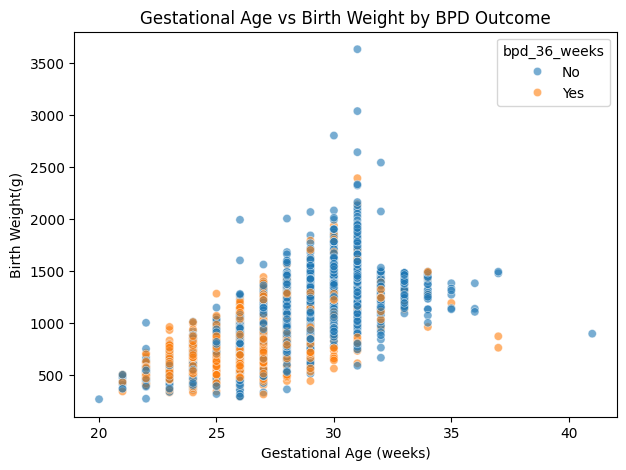

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data= analytical_data,
    x="demograph_birth_ga_weeks",
    y="delivery_birth_weight",
    hue="bpd_36_weeks",
    alpha=0.6
)
plt.title("Gestational Age vs Birth Weight by BPD Outcome")
plt.xlabel("Gestational Age (weeks)")
plt.ylabel("Birth Weight(g)")
plt.show()

In [ ]:
ivh_bpd=pd.crosstab(
    analytical_data["ivh_grade"],
    analytical_data["bpd_36_weeks"],
) * 100
ivh_bpd

bpd_36_weeks,No,Yes
ivh_grade,,
0.0,171600,101600
1.0,21900,24300
2.0,8200,15900
3.0,4900,9900
4.0,10800,12900


In [ ]:
ivh_bpd = pd.crosstab(
    analytical_data["ivh_grade"],
    analytical_data["bpd_36_weeks"]
)

ivh_bpd

bpd_36_weeks,No,Yes
ivh_grade,,
0.0,1716,1016
1.0,219,243
2.0,82,159
3.0,49,99
4.0,108,129


In [ ]:
ivh_bpd_percent = pd.crosstab(
    analytical_data["ivh_grade"],
    analytical_data["bpd_36_weeks"],
    normalize="index"
) * 100

ivh_bpd_percent

bpd_36_weeks,No,Yes
ivh_grade,,
0.0,62.811127,37.188873
1.0,47.402597,52.597403
2.0,34.024896,65.975104
3.0,33.108108,66.891892
4.0,45.569620,54.430380


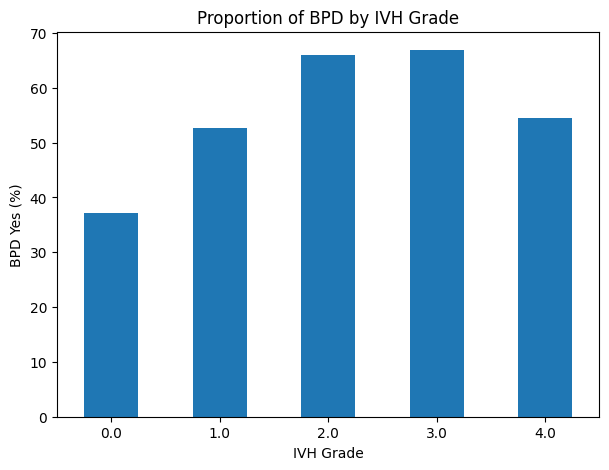

In [ ]:
ivh_bpd_percent["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Proportion of BPD by IVH Grade")
plt.xlabel("IVH Grade")
plt.ylabel("BPD Yes (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
candidate_features = [
    "demograph_birth_ga_weeks",
    "delivery_birth_weight",
    "delivery_apgar_1_min",
    "delivery_apgar_5_min",
    "delivery_steroid_dose",
    "delivery_mode",
    "demograph_gender",
    "multiples",
    "pprom",
    "indication_for_delivery",
    "ivh_grade"
]

analytical_data[candidate_features].isna().sum()

,0
demograph_birth_ga_weeks,0
delivery_birth_weight,6
delivery_apgar_1_min,119
delivery_apgar_5_min,127
delivery_steroid_dose,96
delivery_mode,3
demograph_gender,2
multiples,128
pprom,633
indication_for_delivery,625


In [ ]:
missing_percent= (
    analytical_data[candidate_features]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)
missing_percent

,0
pprom,16.160327
indication_for_delivery,15.956089
multiples,3.267807
delivery_apgar_5_min,3.242277
delivery_apgar_1_min,3.038039
ivh_grade,2.476385
delivery_steroid_dose,2.450855
delivery_birth_weight,0.153178
delivery_mode,0.076589
demograph_gender,0.051059


In [ ]:
analytical_data[
    ["pprom", "indication_for_delivery", "multiples"]
].value_counts(dropna=False)

pprom    indication_for_delivery                       multiples
No       Pre-eclampsia or HELLP                        No           737
         Pre-term labor                                No           601
Yes      Pre-term labor                                No           365
No       Pre-term labor                                Yes          347
NaN      NaN                                           No           340
No       Other                                         No           208
NaN      NaN                                           Yes          130
No       Utero-placental insufficiency                 No           118
         Other                                         Yes          108
         Pre-eclampsia or HELLP                        Yes          102
NaN      NaN                                           NaN           98
Yes      Pre-term labor                                Yes           90
No       Maternal indication other than pre-eclampsia  No            80
Yes      Maternal indication other than pre-eclampsia  No            73
Unknown  Pre-term labor                                No            62
Yes      Other                                         No            55
No       Maternal indication other than pre-eclampsia  Yes           41
         NaN                                           No            40
         Utero-placental insufficiency                 Yes           36
Yes      Maternal indication other than pre-eclampsia  Yes           29
         Utero-placental insufficiency                 No            23
         Pre-eclampsia or HELLP                        No            22
NaN      Pre-term labor                                No            21
Unknown  Pre-eclampsia or HELLP                        No            15
         Unknown or unclear                            No            15
Yes      Other                                         Yes           13
Unknown  Pre-term labor                                Yes           13
No       Unknown or unclear                            No            13
NaN      Pre-eclampsia or HELLP                        No            12
No       Pre-eclampsia or HELLP                        NaN           10
Unknown  Utero-placental insufficiency                 No            10
         Maternal indication other than pre-eclampsia  No             8
         Other                                         No             8
NaN      Utero-placental insufficiency                 No             8
Yes      NaN                                           No             6
NaN      Pre-term labor                                Yes            6
Yes      Unknown or unclear                            No             5
No       NaN                                           NaN            5
         Other                                         NaN            4
NaN      Utero-placental insufficiency                 Yes            3
Unknown  NaN                                           No             3
No       Pre-term labor                                NaN            3
NaN      Unknown or unclear                            No             3
         Pre-eclampsia or HELLP                        Yes            3
         Pre-term labor                                NaN            2
Unknown  Other                                         Yes            2
No       Utero-placental insufficiency                 NaN            2
         NaN                                           Yes            2
         Unknown or unclear                            Yes            2
Unknown  Utero-placental insufficiency                 Yes            2
NaN      Maternal indication other than pre-eclampsia  No             2
Yes      Pre-eclampsia or HELLP                        Yes            2
NaN      Other                                         No             2
Unknown  Unknown or unclear                            Yes            1
         NaN                                   

In [ ]:
analytical_data["pprom"].value_counts(dropna=False)

,count
pprom,
No,2459
Yes,685
NaN,633
Unknown,140


In [ ]:
metadata[metadata["field_name"] == "pprom"]

,field_name,form_name,section_header,field_type,field_label,select_choices_or_calculations,field_note,text_validation_type_or_show_slider_number,text_validation_min,text_validation_max,identifier,branching_logic,required_field,custom_alignment,question_number,matrix_group_name,matrix_ranking,field_annotation
11,pprom,demographics,NaN,radio,Were membranes ruptured for > 24 hours?,"1, Yes | 0, No | 99, Unknown",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
metadata[metadata["field_name"] == "indication_for_delivery"]

,field_name,form_name,section_header,field_type,field_label,select_choices_or_calculations,field_note,text_validation_type_or_show_slider_number,text_validation_min,text_validation_max,identifier,branching_logic,required_field,custom_alignment,question_number,matrix_group_name,matrix_ranking,field_annotation
9,indication_for_delivery,demographics,NaN,dropdown,Indication for delivery:,"1, Pre-term labor | 2, Pre-eclampsia or HELLP ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
metadata.loc[
    metadata["field_name"] == "indication_for_delivery",
    "select_choices_or_calculations"
]

,select_choices_or_calculations
9,"1, Pre-term labor | 2, Pre-eclampsia or HELLP ..."


In [ ]:
candidate_features

['demograph_birth_ga_weeks',
 'delivery_birth_weight',
 'delivery_apgar_1_min',
 'delivery_apgar_5_min',
 'delivery_steroid_dose',
 'delivery_mode',
 'demograph_gender',
 'multiples',
 'pprom',
 'indication_for_delivery',
 'ivh_grade']

In [ ]:
analytical_data[candidate_features].info()

<class 'pandas.core.frame.DataFrame'>
Index: 3917 entries, 0 to 6564
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   demograph_birth_ga_weeks  3917 non-null   float64
 1   delivery_birth_weight     3911 non-null   float64
 2   delivery_apgar_1_min      3798 non-null   float64
 3   delivery_apgar_5_min      3790 non-null   float64
 4   delivery_steroid_dose     3821 non-null   object 
 5   delivery_mode             3914 non-null   object 
 6   demograph_gender          3915 non-null   object 
 7   multiples                 3789 non-null   object 
 8   pprom                     3284 non-null   object 
 9   indication_for_delivery   3292 non-null   object 
 10  ivh_grade                 3820 non-null   float64
dtypes: float64(5), object(6)
memory usage: 367.2+ KB


In [ ]:
analytical_data[candidate_features].info()

<class 'pandas.core.frame.DataFrame'>
Index: 3917 entries, 0 to 6564
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   demograph_birth_ga_weeks  3917 non-null   float64
 1   delivery_birth_weight     3911 non-null   float64
 2   delivery_apgar_1_min      3798 non-null   float64
 3   delivery_apgar_5_min      3790 non-null   float64
 4   delivery_steroid_dose     3821 non-null   object 
 5   delivery_mode             3914 non-null   object 
 6   demograph_gender          3915 non-null   object 
 7   multiples                 3789 non-null   object 
 8   pprom                     3284 non-null   object 
 9   indication_for_delivery   3292 non-null   object 
 10  ivh_grade                 3820 non-null   float64
dtypes: float64(5), object(6)
memory usage: 367.2+ KB


In [ ]:
analytical_data = merged[
    merged["bpd_36_weeks"].isin(["Yes", "No"])
]

In [ ]:
numeric_features = [
    "demograph_birth_ga_weeks",
    "delivery_birth_weight",
    "delivery_apgar_1_min",
    "delivery_apgar_5_min"
]

categorical_features = [
    "delivery_mode",
    "demograph_gender",
    "multiples",
    "pprom",
    "indication_for_delivery"
]

len(numeric_features), len(categorical_features)

(4, 5)

In [ ]:
metadata[metadata["field_name"] =="delivery_steroid_dose"]

,field_name,form_name,section_header,field_type,field_label,select_choices_or_calculations,field_note,text_validation_type_or_show_slider_number,text_validation_min,text_validation_max,identifier,branching_logic,required_field,custom_alignment,question_number,matrix_group_name,matrix_ranking,field_annotation
16,delivery_steroid_dose,perinatal_data,,yesno,Did mother receive at least one dose of steroi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,RH,NaN,NaN,NaN,NaN


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = analytical_data[
    [
        "demograph_birth_ga_weeks",
        "delivery_birth_weight",
        "delivery_apgar_1_min",
        "delivery_apgar_5_min",
        "delivery_mode",
        "demograph_gender",
        "multiples",
        "pprom",
        "indication_for_delivery"
    ]
]

y = analytical_data["bpd_36_weeks"]

In [ ]:
numeric_features=[
    "demograph_birth_ga_weeks",
    "delivery_birth_weight",
    "delivery_apgar_1_min",
    "delivery_apgar_5_min"
]

In [ ]:
categorical_features = [
    "delivery_mode",
    "demograph_gender",
    "multiples",
    "pprom",
    "indication_for_delivery"
]

In [ ]:
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.compose import ColumnTransformer

In [ ]:
from sklearn.impute import SimpleImputer

In [ ]:
numeric_imputer= SimpleImputer(strategy="median")


In [ ]:
categorical_imputer=SimpleImputer(strategy="most_frequent")

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
numeric_pipeline= Pipeline([
    ("imputer", numeric_imputer),
    ("scaler", StandardScaler())
])

In [ ]:
categorical_pipeline= Pipeline([
    ("imputer", categorical_imputer),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))

])

In [ ]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['demograph_birth_ga_weeks',
                                                   'delivery_birth_weight',
                                                   'delivery_apgar_1_min',
                                                   'delivery_apgar_5_min']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['delivery_mode',
                                                   'demograph_gender',
                                                   'multiples', 'pprom',
                                                   'indication_for_delivery'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred=model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy= accuracy_score(y_test, y_pred)
accuracy

0.6301020408163265

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
cm

array([[321, 132],
       [158, 173]])

In [ ]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred, pos_label="Yes")
recall

0.5226586102719033

In [ ]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred, pos_label="Yes")
precision

0.5672131147540984

In [ ]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred, pos_label="Yes")
f1


0.5440251572327044

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)
roc_auc

np.float64(0.6729690615767324)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt_classifier= DecisionTreeClassifier(
    random_state=42

)


In [ ]:
dt_model= Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", dt_classifier)
])

In [ ]:
dt_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['demograph_birth_ga_weeks',
                                                   'delivery_birth_weight',
                                                   'delivery_apgar_1_min',
                                                   'delivery_apgar_5_min']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['delivery_mode',
                                                   'demograph_gender',
                                                   'multiples', 'pprom',
                                                   'indication_for_delivery'])])),
                ('classifier', DecisionTreeClassifier(random_state=42))])

In [ ]:
dt_y_pred=dt_model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score
dt_accuracy=accuracy_score(y_test, dt_y_pred)
dt_accuracy

0.5420918367346939

In [ ]:
dt_train_accuracy = dt_model.score(X_train, y_train)
dt_train_accuracy

0.998723268432812

In [ ]:
DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
dt_classifier_5 = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

In [ ]:
dt_model_5= Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", dt_classifier_5)
])

In [ ]:
dt_model_5.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['demograph_birth_ga_weeks',
                                                   'delivery_birth_weight',
                                                   'delivery_apgar_1_min',
                                                   'delivery_apgar_5_min']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['delivery_mode',
                                                   'demograph_gender',
                                                   'multiples', 'pprom',
                                                   'indication_for_delivery'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
dt_y_pred_5=dt_model_5.predict(X_test)

In [ ]:
dt_accuracy_5=accuracy_score(y_test, dt_y_pred_5)
dt_accuracy_5

0.6403061224489796

In [ ]:
dt_train_accuracy_5= dt_model_5.score(X_train, y_train)
dt_train_accuracy_5

0.6990105330354293

In [ ]:
from sklearn.metrics import precision_score

In [ ]:
dt_precision_5 = precision_score(
    y_test,
    dt_y_pred_5,
    pos_label="Yes"
)

dt_precision_5

0.5830508474576271

In [ ]:
from sklearn.metrics import recall_score

In [ ]:
dt_recall_5 = recall_score(
    y_test,
    dt_y_pred_5,
    pos_label="Yes"
)
dt_recall_5

0.5196374622356495

In [ ]:
from sklearn.metrics import f1_score

In [ ]:
dt_f1_5=f1_score(
    y_test,
    dt_y_pred_5,
    pos_label="Yes"
)
dt_f1_5

0.549520766773163

In [ ]:
dt_y_prob_5=dt_model_5.predict_proba(X_test)[:,1]

In [ ]:
from sklearn.metrics import roc_auc_score

dt_roc_auc_5 = roc_auc_score(
    y_test,
    dt_y_prob_5
)

dt_roc_auc_5

np.float64(0.6618948533776168)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_classifier= RandomForestClassifier(
    n_estimators=100,
    random_state=42

)

In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_classifier)
])

In [ ]:
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['demograph_birth_ga_weeks',
                                                   'delivery_birth_weight',
                                                   'delivery_apgar_1_min',
                                                   'delivery_apgar_5_min']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['delivery_mode',
                                                   'demograph_gender',
                                                   'multiples', 'pprom',
                                                   'indication_for_delivery'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [ ]:
rf_y_pred = rf_model.predict(X_test)

In [ ]:
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_accuracy

0.6275510204081632

In [ ]:
rf_precision = precision_score(
    y_test,
    rf_y_pred,
    pos_label="Yes"
)

rf_precision

0.5596330275229358

In [ ]:
rf_recall = recall_score(
    y_test,
    rf_y_pred,
    pos_label="Yes"
)

rf_recall

0.552870090634441

In [ ]:
rf_f1 = f1_score(
    y_test,
    rf_y_pred,
    pos_label="Yes"
)

rf_f1

0.5562310030395137

In [ ]:
rf_y_prob = rf_model.predict_proba(X_test)[:, 1]

In [ ]:
rf_roc_auc = roc_auc_score(
    y_test,
    rf_y_prob
)

rf_roc_auc

np.float64(0.6726789513348406)

In [ ]:
model_comparison = {
    "Model": [
        "Logistic Regression",
        "Tuned Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.6339,
        0.6403,
        0.6276
    ],
    "Precision": [
        0.5705,
        0.5831,
        0.5596
    ],
    "Recall": [
        0.5378,
        0.5196,
        0.5529
    ],
    "F1": [
        0.5537,
        0.5490,
        0.5562
    ],
    "ROC-AUC": [
        0.6739,
        0.6619,
        0.6727
    ]
}

model_comparison

{'Model': ['Logistic Regression', 'Tuned Decision Tree', 'Random Forest'],
 'Accuracy': [0.6339, 0.6403, 0.6276],
 'Precision': [0.5705, 0.5831, 0.5596],
 'Recall': [0.5378, 0.5196, 0.5529],
 'F1': [0.5537, 0.549, 0.5562],
 'ROC-AUC': [0.6739, 0.6619, 0.6727]}

In [ ]:
import pandas as pd

model_comparison_df = pd.DataFrame(model_comparison)

model_comparison_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.6339,0.5705,0.5378,0.5537,0.6739
1,Tuned Decision Tree,0.6403,0.5831,0.5196,0.5490,0.6619
2,Random Forest,0.6276,0.5596,0.5529,0.5562,0.6727


In [ ]:
model_comparison_percent = model_comparison_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

model_comparison_percent[metric_columns] = (
    model_comparison_percent[metric_columns] * 100
).round(2)

model_comparison_percent

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,63.39,57.05,53.78,55.37,67.39
1,Tuned Decision Tree,64.03,58.31,51.96,54.90,66.19
2,Random Forest,62.76,55.96,55.29,55.62,67.27


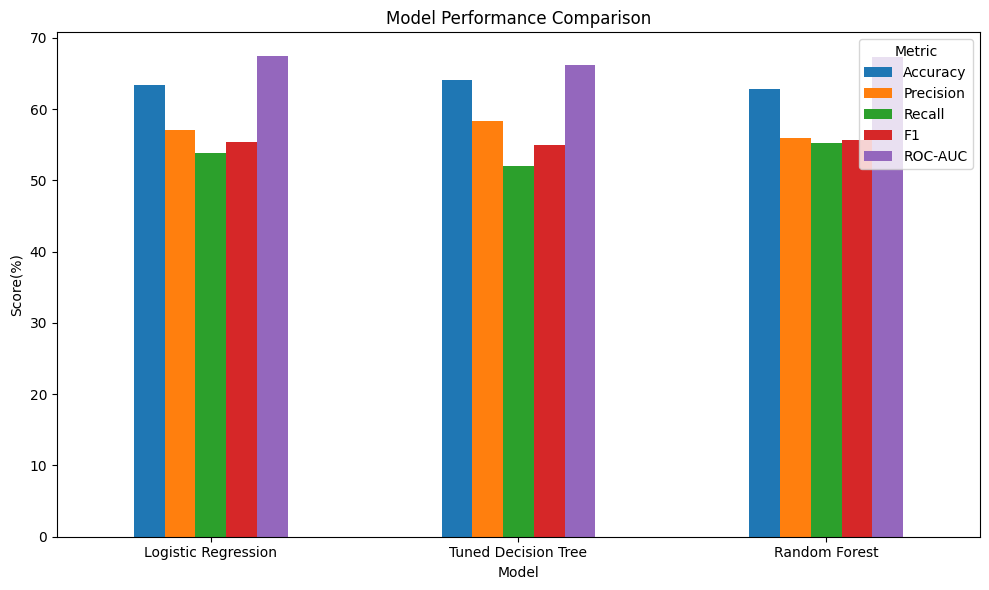

In [ ]:
import matplotlib.pyplot as plt
model_comparison_percent.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]].plot(
    kind="bar",
    figsize=(10,6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score(%)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()


In [ ]:
import xgboost

print(xgboost.__version__)

3.4.1


In [ ]:
from xgboost import XGBClassifier
xgb_classifier=XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

In [ ]:
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_classifier)
])

In [ ]:
y_train_xgb = y_train.map({"No": 0, "Yes": 1})
y_test_xgb = y_test.map({"No": 0, "Yes": 1})

In [ ]:
xgb_model.fit(X_train, y_train_xgb)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['demograph_birth_ga_weeks',
                                                   'delivery_birth_weight',
                                                   'delivery_apgar_1_min',
                                                   'delivery_apgar_5_min']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   On...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [ ]:
xgb_y_pred=xgb_model.predict(X_test)

In [ ]:
xgb_accuracy=(xgb_y_pred==y_test_xgb).mean()
xgb_accuracy

np.float64(0.6033163265306123)

In [ ]:
import numpy as np

xgb_y_pred_labels = np.where(xgb_y_pred == 1, "Yes", "No")

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

xgb_precision = precision_score(y_test, xgb_y_pred_labels, pos_label="Yes")
xgb_recall = recall_score(y_test, xgb_y_pred_labels, pos_label="Yes")
xgb_f1 = f1_score(y_test, xgb_y_pred_labels, pos_label="Yes")

xgb_precision, xgb_recall, xgb_f1

(0.5284090909090909, 0.5619335347432024, 0.5446559297218155)

In [ ]:
xgb_y_prob = xgb_model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score

xgb_roc_auc = roc_auc_score(y_test, xgb_y_prob)
xgb_roc_auc

np.float64(0.6590637775688095)

In [ ]:
model_comparison["Model"].append("XGBoost")
model_comparison["Accuracy"].append(xgb_accuracy)
model_comparison["Precision"].append(xgb_precision)
model_comparison["Recall"].append(xgb_recall)
model_comparison["F1"].append(xgb_f1)
model_comparison["ROC-AUC"].append(xgb_roc_auc)

In [ ]:
model_comparison_df = pd.DataFrame(model_comparison)
model_comparison_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.633900,0.570500,0.537800,0.553700,0.673900
1,Tuned Decision Tree,0.640300,0.583100,0.519600,0.549000,0.661900
2,Random Forest,0.627600,0.559600,0.552900,0.556200,0.672700
3,XGBoost,0.603316,0.528409,0.561934,0.544656,0.659064


In [ ]:
model_comparison_percent = model_comparison_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

model_comparison_percent[metric_columns] = (
    model_comparison_percent[metric_columns] * 100
).round(2)

model_comparison_percent

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,63.39,57.05,53.78,55.37,67.39
1,Tuned Decision Tree,64.03,58.31,51.96,54.90,66.19
2,Random Forest,62.76,55.96,55.29,55.62,67.27
3,XGBoost,60.33,52.84,56.19,54.47,65.91


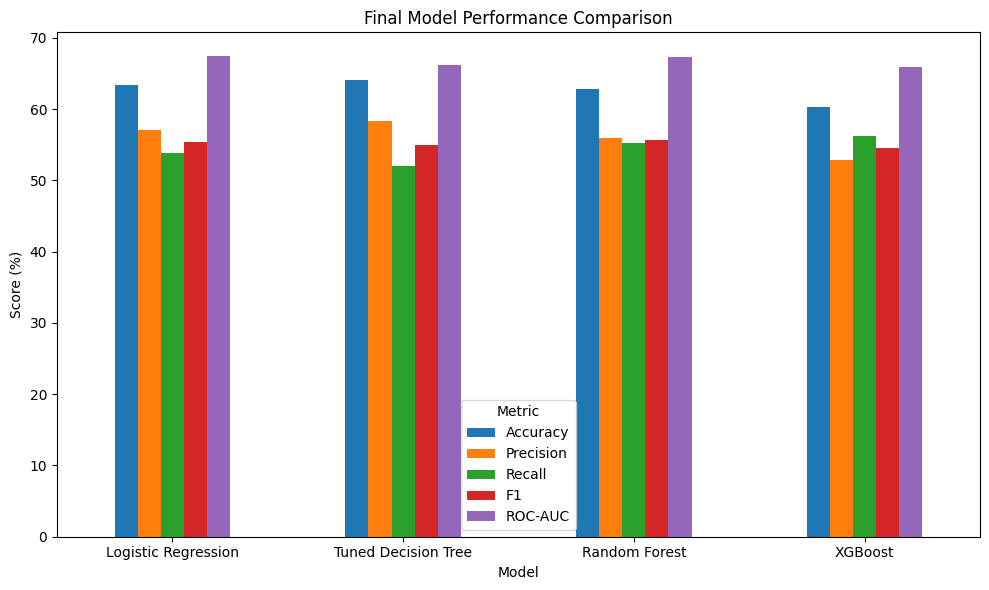

In [ ]:
import matplotlib.pyplot as plt

model_comparison_percent.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [ ]:
feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()
xgb_importance = xgb_model.named_steps["classifier"].feature_importances_
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importance
}).sort_values(
    by="Importance",
    ascending=False
)
feature_importance_df.head(15)

,Feature,Importance
0,num__demograph_birth_ga_weeks,0.082144
15,cat__indication_for_delivery_Other,0.081888
19,cat__indication_for_delivery_Utero-placental i...,0.080256
1,num__delivery_birth_weight,0.071703
12,cat__pprom_Unknown,0.070068
16,cat__indication_for_delivery_Pre-eclampsia or ...,0.057463
4,cat__delivery_mode_C-section,0.053266
3,num__delivery_apgar_5_min,0.052822
9,cat__multiples_No,0.052560
17,cat__indication_for_delivery_Pre-term labor,0.051991


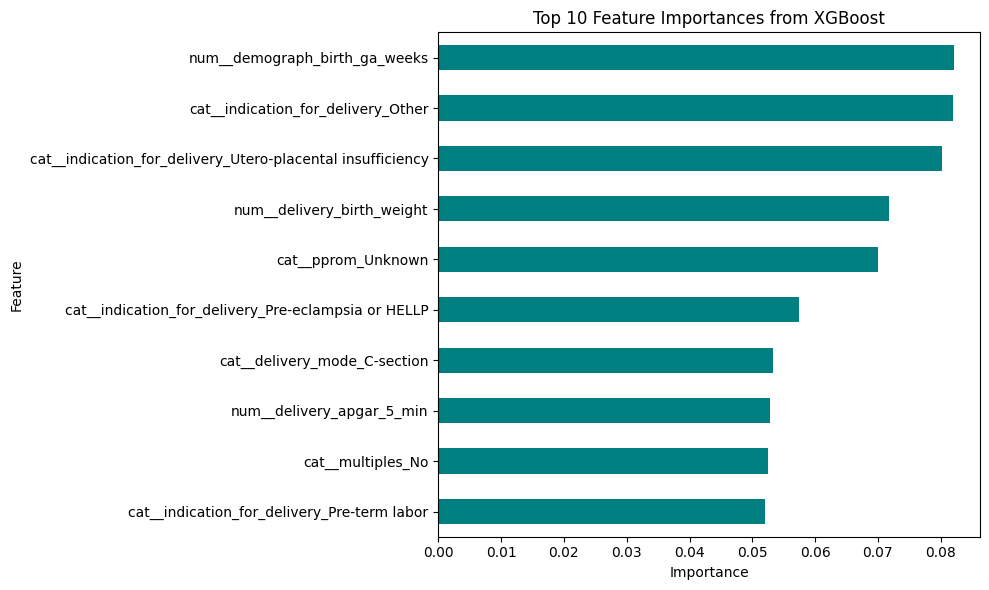

In [ ]:
feature_importance_df.head(10).sort_values(
    by="Importance"
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    figsize=(10, 6),
    legend=False,
    color="teal"
)

plt.title("Top 10 Feature Importances from XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

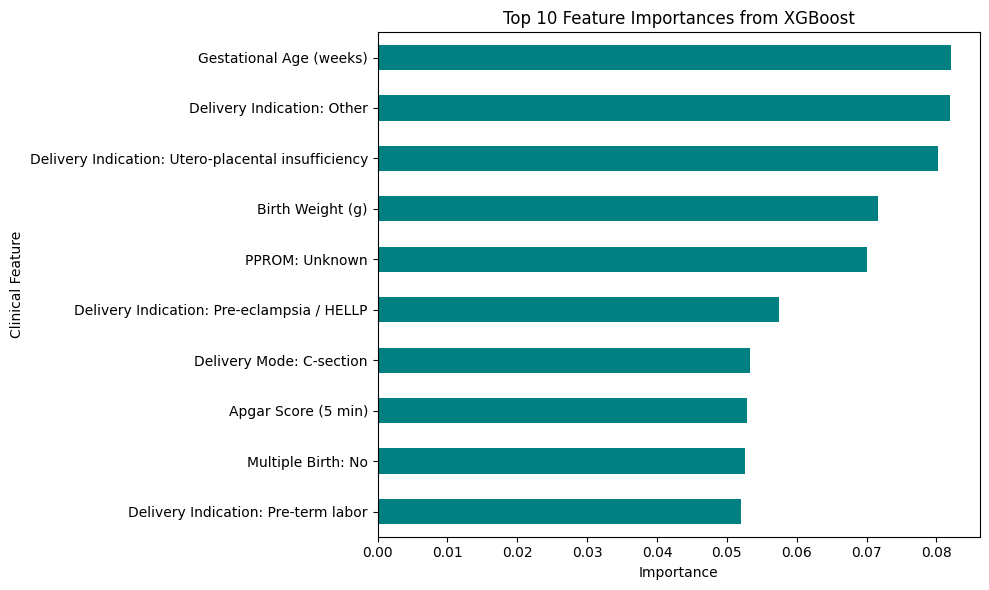

In [ ]:
clean_labels = {
    "num__demograph_birth_ga_weeks": "Gestational Age (weeks)",
    "cat__indication_for_delivery_Other": "Delivery Indication: Other",
    "cat__indication_for_delivery_Utero-placental insufficiency": "Delivery Indication: Utero-placental insufficiency",
    "num__delivery_birth_weight": "Birth Weight (g)",
    "cat__pprom_Unknown": "PPROM: Unknown",
    "cat__indication_for_delivery_Pre-eclampsia or HELLP": "Delivery Indication: Pre-eclampsia / HELLP",
    "cat__delivery_mode_C-section": "Delivery Mode: C-section",
    "num__delivery_apgar_5_min": "Apgar Score (5 min)",
    "cat__multiples_No": "Multiple Birth: No",
    "cat__indication_for_delivery_Pre-term labor": "Delivery Indication: Pre-term labor"
}

top10_clean = feature_importance_df.head(10).copy()

top10_clean["Feature"] = top10_clean["Feature"].replace(clean_labels)

top10_clean.sort_values(
    by="Importance"
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    figsize=(10, 6),
    legend=False,
    color="teal"
)

plt.title("Top 10 Feature Importances from XGBoost")
plt.xlabel("Importance")
plt.ylabel("Clinical Feature")
plt.tight_layout()
plt.show()

In [ ]:
model_comparison_percent = model_comparison_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

model_comparison_percent[metric_columns] = (
    model_comparison_percent[metric_columns] * 100
).round(2)

model_comparison_percent

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,63.39,57.05,53.78,55.37,67.39
1,Tuned Decision Tree,64.03,58.31,51.96,54.90,66.19
2,Random Forest,62.76,55.96,55.29,55.62,67.27
3,XGBoost,60.33,52.84,56.19,54.47,65.91


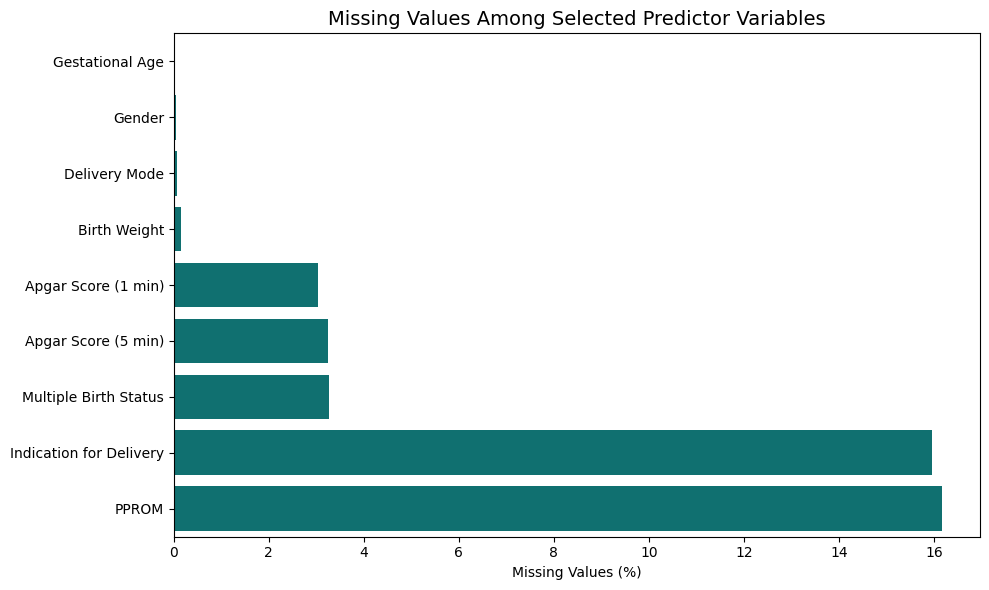

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

selected_features = [
    "demograph_birth_ga_weeks",
    "delivery_birth_weight",
    "delivery_apgar_1_min",
    "delivery_apgar_5_min",
    "delivery_mode",
    "demograph_gender",
    "multiples",
    "pprom",
    "indication_for_delivery"
]

missing_percent = (
    analytical_data[selected_features]
    .isnull()
    .mean()
    .mul(100)
)

# Use readable labels for the report
display_names = {
    "demograph_birth_ga_weeks": "Gestational Age",
    "delivery_birth_weight": "Birth Weight",
    "delivery_apgar_1_min": "Apgar Score (1 min)",
    "delivery_apgar_5_min": "Apgar Score (5 min)",
    "delivery_mode": "Delivery Mode",
    "demograph_gender": "Gender",
    "multiples": "Multiple Birth Status",
    "pprom": "PPROM",
    "indication_for_delivery": "Indication for Delivery"
}

missing_percent.index = missing_percent.index.map(display_names)
missing_percent = missing_percent.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index,
    color="teal"
)

plt.title(
    "Missing Values Among Selected Predictor Variables",
    fontsize=14
)
plt.xlabel("Missing Values (%)")
plt.ylabel("")
plt.xlim(left=0)
plt.tight_layout()

plt.savefig(
    "missing_data_overview.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
